# Illustrations

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#### Figure 2

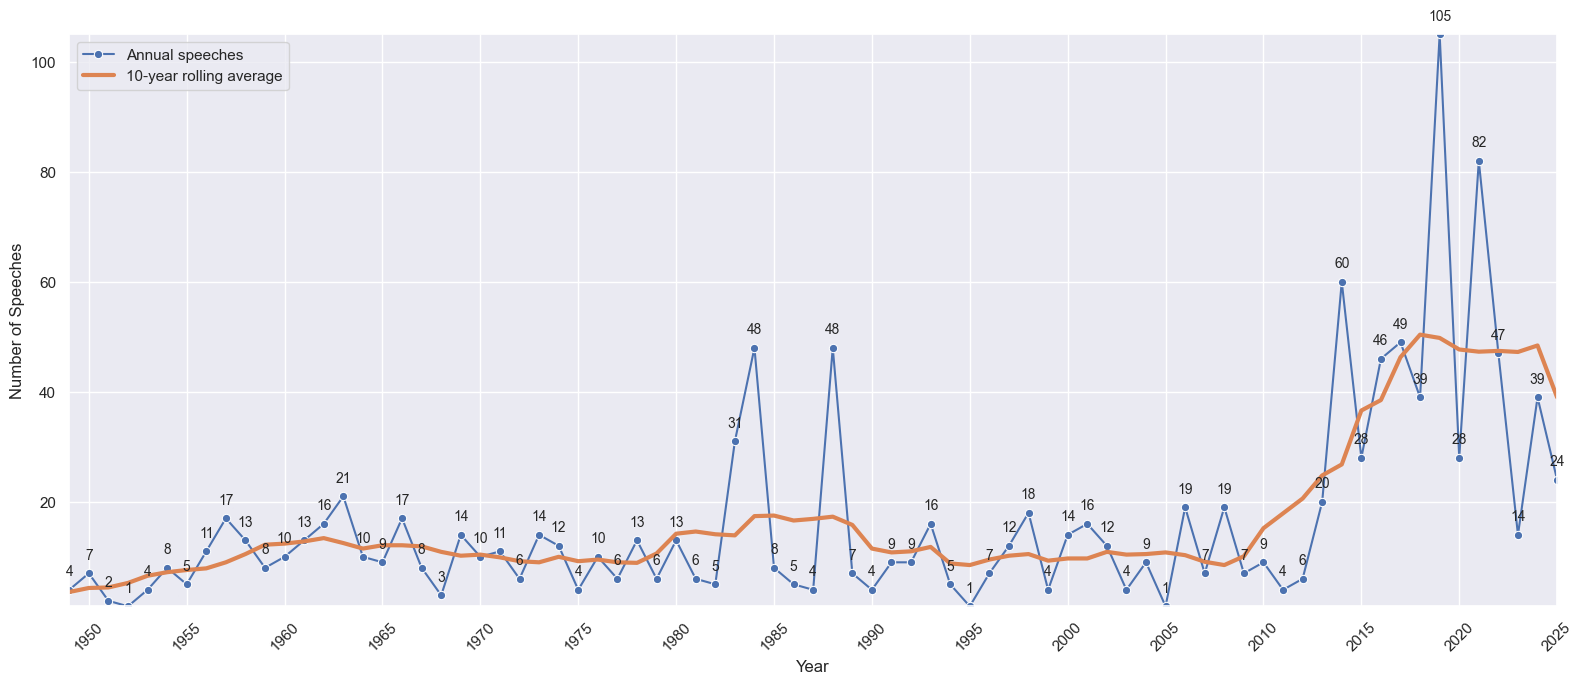

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_2 = pd.read_csv("tables/speech_number_df_1949-2025.csv", index_col=False)
df_2 = df_2.sort_values("Year")

df_2["10-year rolling average"] = (
    df_2["No. of Speeches"]
    .rolling(window=10, center=True, min_periods=1)
    .mean()
)

sns.set_theme(style="darkgrid")

plt.figure(figsize=(16, 7))

ax = sns.lineplot(
    data=df_2,
    x="Year",
    y="No. of Speeches",
    marker="o",
    linewidth=1.5,
    label="Annual speeches"
)

sns.lineplot(
    data=df_2,
    x="Year",
    y="10-year rolling average",
    linewidth=3,
    label="10-year rolling average"
)

plt.xticks(
    ticks=range(1950, 2026, 5),
    rotation=45
)

for _, row in df_2.iterrows():
    ax.text(
        row["Year"],
        row["No. of Speeches"] + 2,
        int(row["No. of Speeches"]),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.margins(x=0,y=0)
#plt.title("Number of Speeches per Year, 1949-2025", fontsize=24)
plt.xlabel("Year")
plt.ylabel("Number of Speeches")
plt.legend()
plt.tight_layout()

plt.savefig(
    "figures/figure_2.jpeg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#### Figure 3

In [3]:
df_3 = pd.read_csv("tables/topics counts 1949-1988.csv", index_col=False)

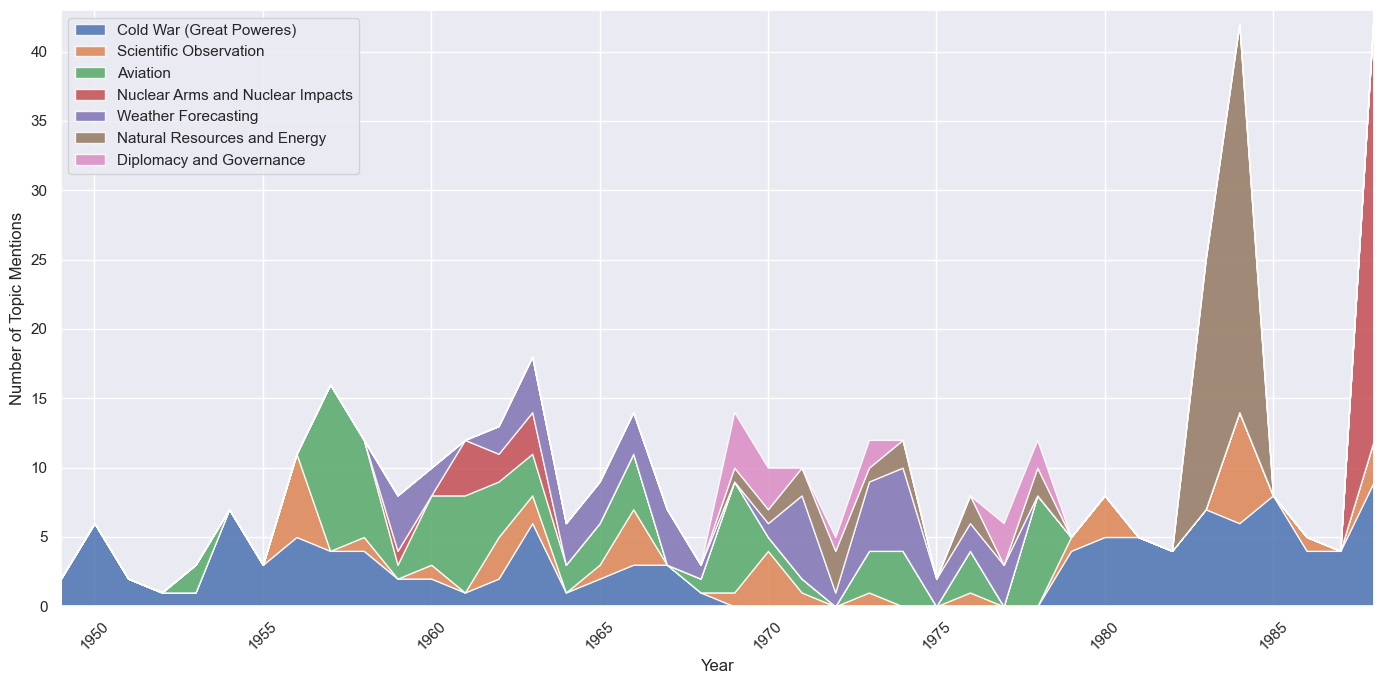

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_3 = pd.read_csv("tables/topics counts 1949-1988.csv", index_col=False)
df_3 = df_3.sort_values("Year")

sns.set_theme(style="darkgrid")

topic_cols = [col for col in df_3.columns if col != "Year"]

plt.figure(figsize=(14, 7))

plt.stackplot(
    df_3["Year"],
    [df_3[col] for col in topic_cols],
    labels=topic_cols,
    alpha=0.85
)

plt.xticks(
    ticks=range(1950, 1989, 5),
    rotation=45
)

#plt.title("Topic Counts in Speeches, 1949-1988", fontsize=24)
plt.xlabel("Year")
plt.ylabel("Number of Topic Mentions")
#plt.legend(loc="center", bbox_to_anchor=(1.02, 1))
plt.legend()
plt.tight_layout()
plt.margins(x=0,y=0)

plt.savefig(
    "figures/figure_3.jpeg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#### Figure 4

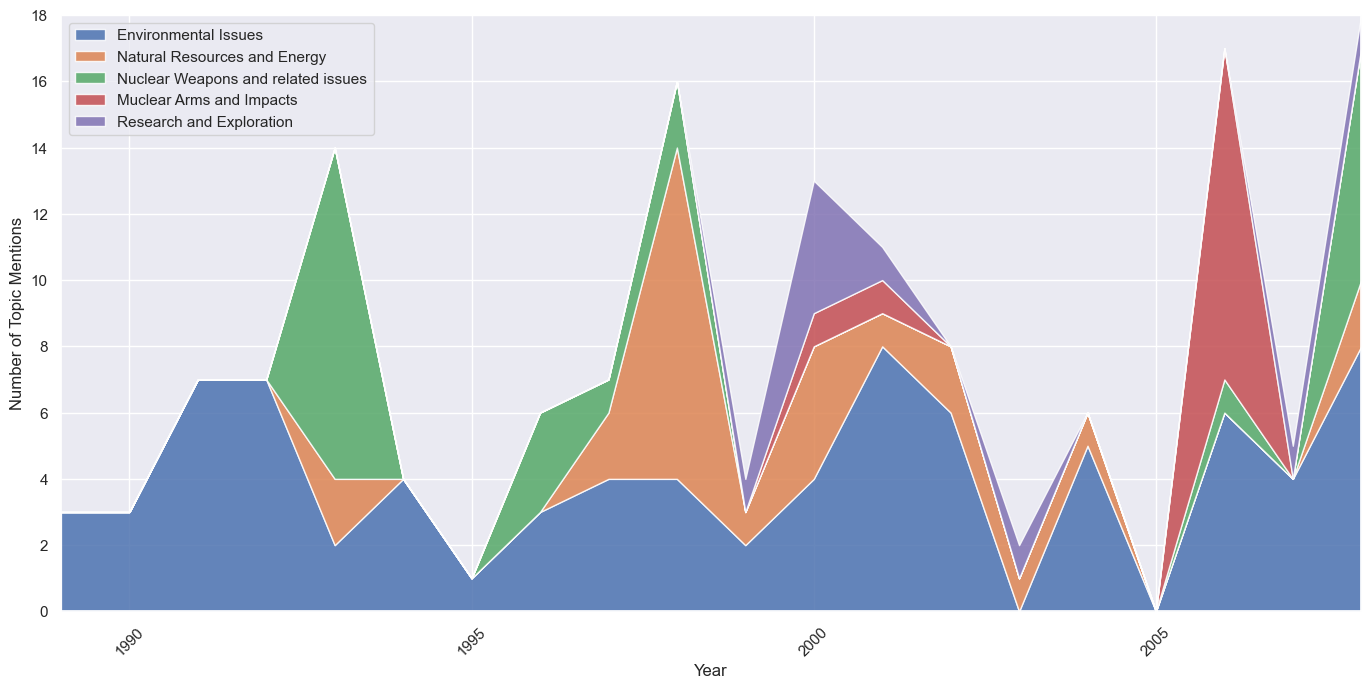

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_4 = pd.read_csv("tables/topics counts 1989-2008.csv", index_col=False)
df_4 = df_4.sort_values("Year")

sns.set_theme(style="darkgrid")

topic_cols = [col for col in df_4.columns if col != "Year"]

plt.figure(figsize=(14, 7))

plt.stackplot(
    df_4["Year"],
    [df_4[col] for col in topic_cols],
    labels=topic_cols,
    alpha=0.85
)

plt.xticks(
    ticks=range(1990, 2009, 5),
    rotation=45
)

#plt.title("Topic Counts in Speeches, 1989-2008", fontsize=24)
plt.xlabel("Year")
plt.ylabel("Number of Topic Mentions")
plt.legend(loc="best")
plt.tight_layout()
plt.margins(x=0,y=0)



plt.savefig(
    "figures/figure_4.jpeg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Figure 5

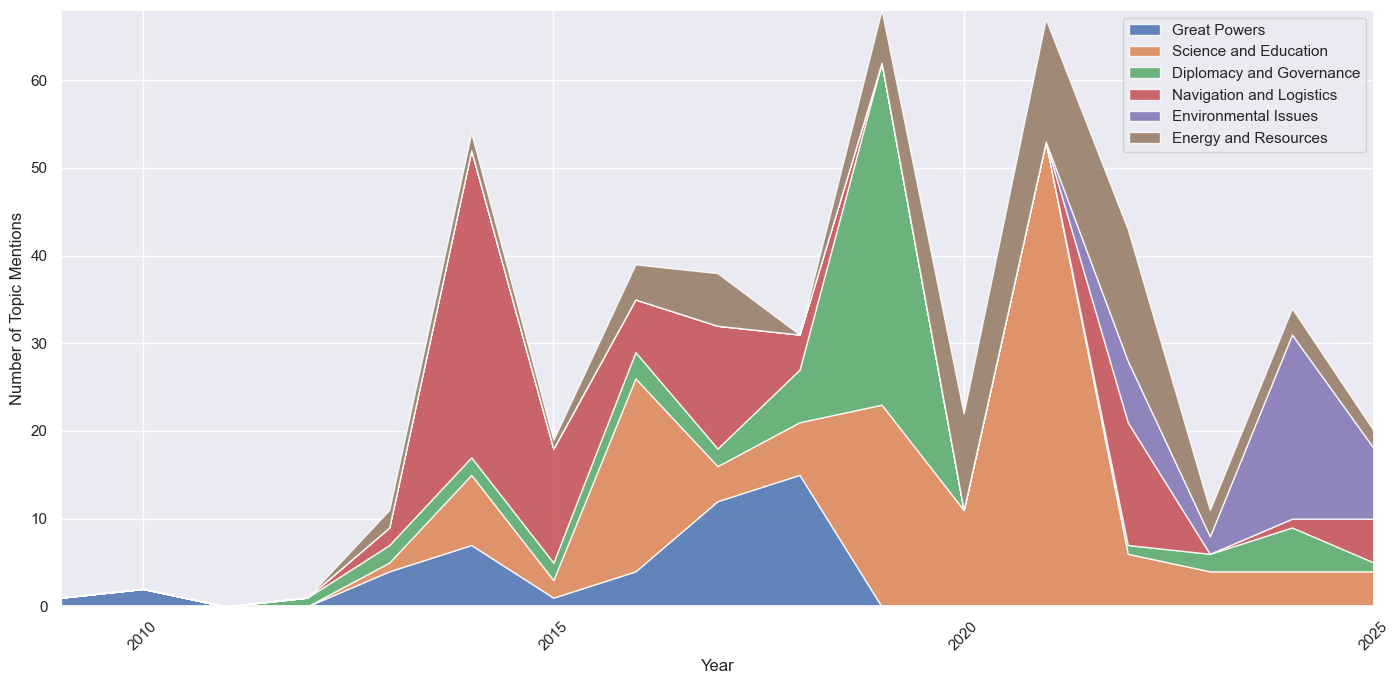

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_5 = pd.read_csv("tables/topics counts 2009-2025.csv", index_col=False)
df_5 = df_5.sort_values("Year")

sns.set_theme(style="darkgrid")

topic_cols = [col for col in df_5.columns if col != "Year"]

plt.figure(figsize=(14, 7))

plt.stackplot(
    df_5["Year"],
    [df_5[col] for col in topic_cols],
    labels=topic_cols,
    alpha=0.85
)

plt.xticks(
    ticks=range(2010, 2026, 5),
    rotation=45
)

#plt.title("Topic Counts in Speeches, 2009-2025", fontsize=24)
plt.xlabel("Year")
plt.ylabel("Number of Topic Mentions")
plt.legend(loc="best")
plt.tight_layout()
plt.margins(x=0,y=0)



plt.savefig(
    "figures/figure_5.jpeg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#### Parties

In [11]:
df = pd.read_csv("tables/Parties.csv",index_col=False)
df

,Period,LDP,LDP and Komeito Coallition,Major Opposition
0,1949-1958,11,NaN,18
1,1959-1968,23,NaN,34
2,1969-1978,14,NaN,21
3,1979-1988,21,NaN,55
4,1989-1998,11,NaN,12
5,1999-2008,34,43.0,23
6,2009-2018,89,132.0,33
7,2019-2025,105,127.0,32


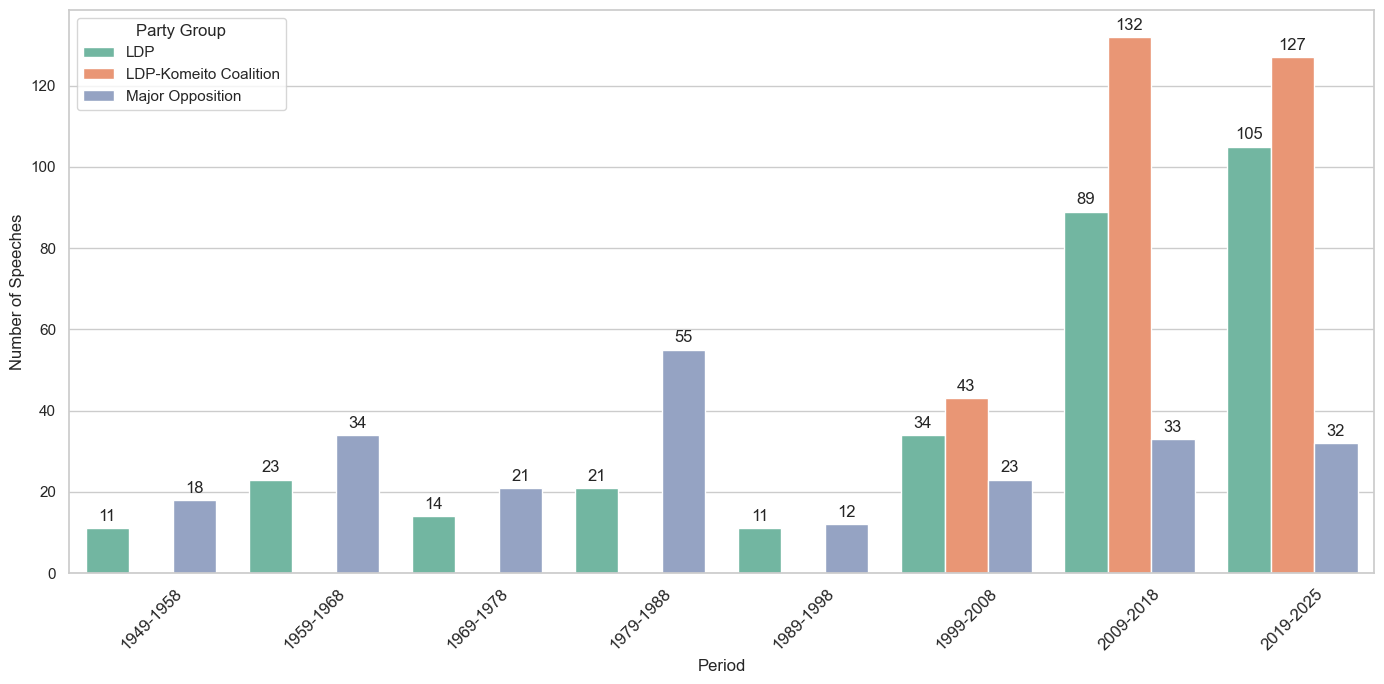

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("tables/Parties.csv", index_col=False)

# Fix column name typo if you want cleaner labels
df = df.rename(columns={
    "LDP and Komeito Coallition": "LDP-Komeito Coalition"
})

# Convert wide data to long format for seaborn
df_long = df.melt(
    id_vars="Period",
    var_name="Party Group",
    value_name="No. of Speeches"
)

df_long["No. of Speeches"] = pd.to_numeric(
    df_long["No. of Speeches"],
    errors="coerce"
)

sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=df_long,
    x="Period",
    y="No. of Speeches",
    hue="Party Group",
    palette="Set2"
)

# Add values above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        fontsize=12,
        padding=3
    )

#plt.title("Number of Speeches by Party Group and Period", fontsize = 20)
plt.xlabel("Period")
plt.ylabel("Number of Speeches")
plt.xticks(rotation=45, fontsize = 12)
plt.legend(title="Party Group")
plt.tight_layout()

plt.savefig(
    "figures/figure_6.jpeg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
